In [4]:
# Import basic libararies

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [5]:
df = pd.read_csv('Dataset/phishing_site_urls.csv')

In [6]:
df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [7]:
df.shape

(549346, 2)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 549346 entries, 0 to 549345
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   URL     549346 non-null  str  
 1   Label   549346 non-null  str  
dtypes: str(2)
memory usage: 8.4 MB


In [9]:
df.isnull().sum()

URL      0
Label    0
dtype: int64

In [10]:
df.Label.value_counts()

Label
good    392924
bad     156422
Name: count, dtype: int64

In [11]:
from nltk.tokenize import RegexpTokenizer

In [12]:
tokenizer = RegexpTokenizer(r'[A-Za-z]+')

In [13]:
df.URL[0]

'nobell.it/70ffb52d079109dca5664cce6f317373782/login.SkyPe.com/en/cgi-bin/verification/login/70ffb52d079109dca5664cce6f317373/index.php?cmd=_profile-ach&outdated_page_tmpl=p/gen/failed-to-load&nav=0.5.1&login_access=1322408526'

In [14]:
tokenizer.tokenize(df.URL[0])

['nobell',
 'it',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'login',
 'SkyPe',
 'com',
 'en',
 'cgi',
 'bin',
 'verification',
 'login',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'index',
 'php',
 'cmd',
 'profile',
 'ach',
 'outdated',
 'page',
 'tmpl',
 'p',
 'gen',
 'failed',
 'to',
 'load',
 'nav',
 'login',
 'access']

In [15]:
df['text_tokenized'] = df.URL.map(lambda t : tokenizer.tokenize(t))

In [16]:
df.head()

,URL,Label,text_tokenized
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe..."
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin..."
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int..."
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex..."
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi..."


In [17]:
from nltk.stem.snowball import SnowballStemmer

In [18]:
stemmer = SnowballStemmer('english')

In [19]:
df['text_stemmed'] = df['text_tokenized'].map(lambda l: [stemmer.stem(word) for word in l])

In [20]:
df.head()

,URL,Label,text_tokenized,text_stemmed
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,..."
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin..."
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into..."
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp..."
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide..."


In [21]:
df['text'] = df['text_stemmed'].map(lambda l: ' '.join(l))

In [22]:
df.head()

,URL,Label,text_tokenized,text_stemmed,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [23]:
good_sites = df[df.Label == 'good']
bad_sites = df[df.Label == 'bad']

In [24]:
good_sites.head()

,URL,Label,text_tokenized,text_stemmed,text
18231,esxcc.com/js/index.htm?us.battle.net/noghn/en/...,good,"[esxcc, com, js, index, htm, us, battle, net, ...","[esxcc, com, js, index, htm, us, battl, net, n...",esxcc com js index htm us battl net noghn en r...
18232,wwweira¯&nvinip¿ncH¯wVö%ÆåyDaHðû/ÏyEùuË\nÓ6...,good,"[www, eira, nvinip, ncH, wV, yDaH, yE, u, rT, ...","[www, eira, nvinip, nch, wv, ydah, ye, u, rt, ...",www eira nvinip nch wv ydah ye u rt u g m i xz...
18233,'www.institutocgr.coo/web/media/syqvem/dk-óij...,good,"[www, institutocgr, coo, web, media, syqvem, d...","[www, institutocgr, coo, web, media, syqvem, d...",www institutocgr coo web media syqvem dk ij r ...
18234,Yìê koãÕ»Î§DéÎl½ñ¡ââqtò¸/à; Í,good,"[Y, ko, D, l, qt]","[y, ko, d, l, qt]",y ko d l qt
18236,ruta89fm.com/images/AS@Vies/1i75cf7b16vc<Fd16...,good,"[ruta, fm, com, images, AS, Vies, i, cf, b, vc...","[ruta, fm, com, imag, as, vie, i, cf, b, vc, f...",ruta fm com imag as vie i cf b vc f d b g sd v...


In [25]:
def plot_wordcloud(text, mask=None, max_words=400, max_font_size=120,
                   figure_size=(24.0, 16.0), title=None,
                   title_size=40, image_color=False):

    stopwords = set(STOPWORDS)
    more_stopwords = {'com', 'http'}
    stopwords = stopwords.union(more_stopwords)

    wordcloud = WordCloud(
        background_color='white',
        stopwords=stopwords,
        max_words=max_words,
        max_font_size=max_font_size,
        random_state=42,
        mask=mask
    )

    wordcloud.generate(text)

    plt.figure(figsize=figure_size)

    if image_color:
        image_colors = ImageColorGenerator(mask)
        plt.imshow(
            wordcloud.recolor(color_func=image_colors),
            interpolation="bilinear"
        )
        plt.title(
            title,
            fontdict={
                'size': title_size,
                'verticalalignment': 'bottom'
            }
        )

    else:
        plt.imshow(wordcloud)
        plt.title(
            title,
            fontdict={
                'size': title_size,
                'color': 'green',
                'verticalalignment': 'bottom'
            }
        )

    plt.axis("off")
    plt.tight_layout()

In [26]:
good_text = ' '.join(good_sites['text'].tolist())

bad_text = ' '.join(bad_sites['text'].tolist())

In [27]:
from wordcloud import WordCloud

In [28]:
import matplotlib.pyplot as plt

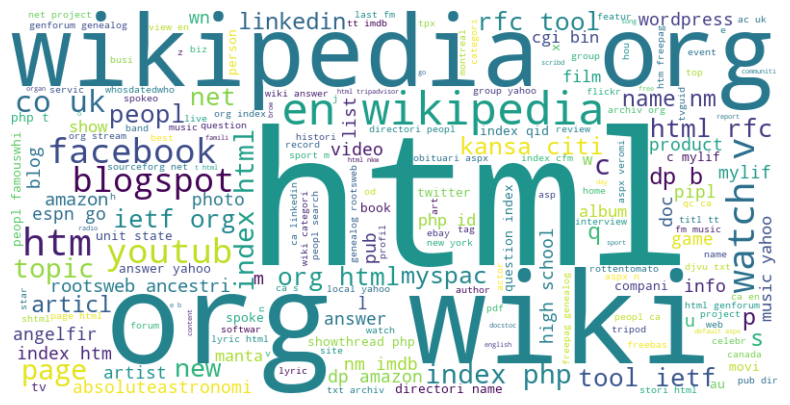

In [30]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(good_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

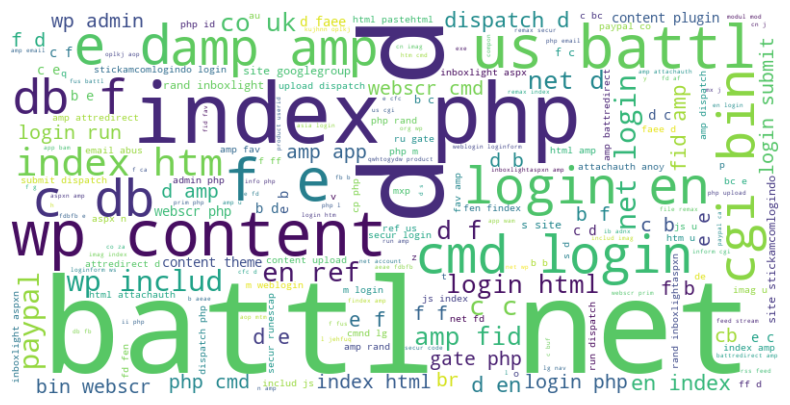

In [31]:
# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(bad_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [32]:
df.head()

,URL,Label,text_tokenized,text_stemmed,text
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['text'],
    df['Label'],
    test_size=0.2,
    random_state=42,
    stratify=df['Label']
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

Training samples: 439476
Testing samples: 109870


In [35]:
cv_new = CountVectorizer()

X_train = cv_new.fit_transform(X_train_text)

X_test = cv_new.transform(X_test_text)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (439476, 304419)
Testing features: (109870, 304419)


In [36]:
from sklearn.feature_extraction.text import CountVectorizer

In [37]:
cv =  CountVectorizer()

In [38]:
features = cv.fit_transform(df.text)

In [39]:
features[:5].toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(5, 350837))

In [42]:
from sklearn.model_selection import train_text_split

ImportError: cannot import name 'train_text_split' from 'sklearn.model_selection' (C:\Users\Vanshika Kotwal\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\__init__.py)

In [41]:
x_train, x_test, y_train, y_test = train_test_split(features, df.Label)


In [43]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (439476, 350837)
Testing data: (109870, 350837)


Model Training

In [45]:
from sklearn.linear_model import LogisticRegression

model_new = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='liblinear'
)

model_new.fit(x_train, y_train)

print("Model trained successfully!")

print("Training accuracy:", model_new.score(x_train, y_train))

print("Testing accuracy:", model_new.score(x_test, y_test))

Model trained successfully!
Training accuracy: 0.986781842144225
Testing accuracy: 0.971122130234387


In [47]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

y_pred_new = model_new.predict(x_test)

print("CLASSIFICATION REPORT")

print(classification_report(y_test, y_pred_new))

print("CONFUSION MATRIX")

print(confusion_matrix(
    y_test,
    y_pred_new,
    labels=['bad', 'good']
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         bad       0.95      0.95      0.95     39187
        good       0.98      0.98      0.98     98150

    accuracy                           0.97    137337
   macro avg       0.96      0.97      0.96    137337
weighted avg       0.97      0.97      0.97    137337

CONFUSION MATRIX
[[37386  1801]
 [ 2165 95985]]


In [49]:
model_new.fit(x_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strengt

In [50]:
model_new.score(x_test, y_test)

0.971122130234387

In [51]:
model_new.score(x_train, y_train)

0.986781842144225

In [52]:
from sklearn.metrics import classification_report

In [57]:
from sklearn.metrics import confusion_matrix

conf_mat = pd.DataFrame(
    confusion_matrix(model_new.predict(x_test), y_test),
    columns=['Actual:Bad', 'Actual:Good'],
    index=['Predicted:Bad', 'Predicted:Good']
)

In [58]:
import seaborn as sns

CONFUSION MATRIX


<Axes: >

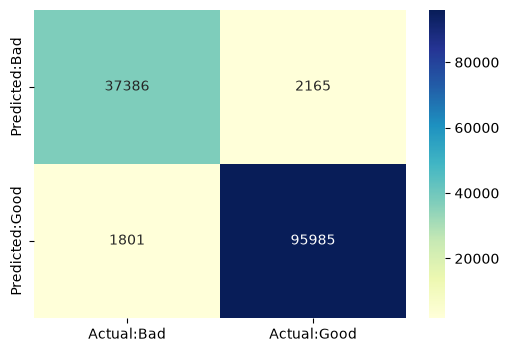

In [59]:
print("CONFUSION MATRIX")

plt.figure(figsize=(6,4))

sns.heatmap(conf_mat, annot=True, fmt='d', cmap='YlGnBu')


In [60]:
from sklearn.naive_bayes import MultinomialNB

In [61]:
mnb = MultinomialNB()

In [62]:
mnb.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[117235.,294774.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-1.26,-0.33]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U4](2,)","['bad','good']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 350837)","[[869., 86., 9.,..., 0., 0., 2.], [486.,146., 2.,..., 0., 7., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 350837)","[[ -7.35, -9.66,-11.82,...,-14.12,-14.12,-13.02], [ -8.43, -9.63,-13.52,...,-14.62,-12.54,-14.62]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,350837


In [63]:
mnb.score(x_train, y_train)

0.9741534772298663

Save Model

In [64]:
import pickle

In [66]:
pickle.dump(model_new, open('phishing.pkl', 'wb'))

In [77]:
pickle.dump(model_new, open('phishing_mnb.pkl', 'wb'))

In [67]:
pickle.dump(cv, open("vectorizer.pkl", 'wb'))

In [69]:
predict_bad = [  "http://paypal-update-account.com",
    "http://secure-login-paypal.com",
    "http://appleid-verify-account.com",
    "http://login-microsoft-security.com",
    "http://amazon-account-verification.com",
    "http://google-security-check.com",
    "http://facebook-login-verify.com",
    "http://bankofamerica-secure-login.com",
    "http://netflix-account-update.com",
    "http://update-your-password-security.com" ]

In [70]:
predict_good = [  "https://www.google.com",
    "https://www.youtube.com",
    "https://www.wikipedia.org",
    "https://www.microsoft.com",
    "https://www.amazon.in",
    "https://www.github.com",
    "https://www.python.org",
    "https://www.nptel.ac.in",
    "https://www.openai.com",
    "https://www.linkedin.com" ]

In [71]:
predict_good = cv.transform(predict_good)

In [72]:
predict_bad = cv.transform(predict_bad)

In [75]:
model_new.predict(predict_good)

array(['bad', 'bad', 'good', 'bad', 'bad', 'bad', 'good', 'bad', 'bad',
       'good'], dtype=object)

In [74]:
model_new.predict(predict_bad)

array(['bad', 'bad', 'bad', 'bad', 'bad', 'bad', 'bad', 'bad', 'bad',
       'bad'], dtype=object)

In [78]:
mnb.predict(predict_good)

array(['bad', 'bad', 'good', 'bad', 'bad', 'bad', 'bad', 'bad', 'bad',
       'bad'], dtype='<U4')